# Step 5: When did each member go quiet?

Most members have a month where their activity falls away for good. If those months are spread
out, people faded one at a time. If they cluster, something happened to the room. (Spread-out
dates don't rule out a shared cause, though: see "What the dates don't tell you" below.)

## Pre-registration

These decisions were written into `sql/05_changepoints.sql` before any results existed, so the
rule couldn't be adjusted to fit the results:

1. **The rule.** Monthly counts on a complete grid (zero months filled in) → trailing 3-month
   mean (that month and the two before it, which smooths out one-off quiet months) → each
   member's personal peak → change point = the first month below 50% of that peak that never
   recovers. As a sensitivity check, the rule is re-run at 40% and 60%, to see whether the
   result depends on the exact cut-off.
2. **Departures are excluded.** `user_20`, `user_21` and `user_26` left or went dormant, a known
   cause rather than a change in behaviour. They're reported separately.
3. **The tournament calendar is checked.** A member who mostly posts during tournaments would
   show a change point when a tournament ends.
4. **The prediction:** Steps 1, 3 and 4 found the whole room thinning evenly, so change points
   should cluster.

## Result: the prediction was wrong

**21 of 24 members have a change point**, spread across 39 months (2021-10 to 2025-01, median
2023-01): a staircase, not a cliff.

**Three members have no change point:** `user_06`, `user_15` and `user_24`. That doesn't mean
they never declined: all three dipped below half their peak for months and came back (longest
spells 11, 17 and 6 months), and under the six-month-recovery variant `user_06` gets a change
point. At the end of the archive they're at **58%, 54% and 92% of their own peak** (per-day
rates, since the final month, 2026-08, has only 9 days).

Two of their monthly peaks fall in tournament months, so their peaks were checked without those
months:

| | best year | peak without tournament months | 2022 → 2025 |
|---|---|---|---|
| `user_15` | **2025** | 2025-07 | **+37%** |
| `user_24` | **2024** | 2025-01 | **+29%** |
| `user_06` | 2022 | 2022-09 | **−35%** |

`user_15` and `user_24` peaked during the decline and grew. `user_06` peaked in 2022 and declined,
but at half the server's rate (−35% against −69%). Together their share of the server went from
**3.0% in 2021 to 18.2% in 2026** (3.2% → 22.1% of the 24 analysed members).

So the change points describe when people declined among those who did; not everyone did.

In [1]:
import re
import os
import warnings
import psycopg2
import pandas as pd

warnings.filterwarnings("ignore", message=".*only supports SQLAlchemy.*")

REPO_ROOT = os.path.dirname(os.getcwd()) if os.path.basename(os.getcwd()) == "notebooks" else os.getcwd()
SQL_PATH = os.path.join(REPO_ROOT, "sql", "05_changepoints.sql")
TABLES_DIR = os.path.join(REPO_ROOT, "outputs", "tables")
os.makedirs(TABLES_DIR, exist_ok=True)

def load_labeled_queries(path):
    with open(path, encoding="utf-8") as f:
        sql = f.read()
    parts = re.split(r"--\s*QUERY:\s*(\w+)", sql)
    return {name: body.strip().rstrip(";") for name, body in zip(parts[1::2], parts[2::2])}

queries = load_labeled_queries(SQL_PATH)
print(f"Loaded {len(queries)} labeled queries: {list(queries.keys())}")

Loaded 4 labeled queries: ['member_month_activity', 'member_first_last_month', 'server_month_totals', 'member_month_text']


In [2]:
try:
    conn = psycopg2.connect(host="localhost", port=5432, dbname="postgres", user="postgres",
                            options="-c timezone=Europe/Bucharest")
except psycopg2.OperationalError:
    conn = None
    print("No database connection: using the saved tables in outputs/tables/.")
if conn is not None:
    for name, sql in queries.items():
        df = pd.read_sql(sql, conn)
        df.to_csv(os.path.join(TABLES_DIR, f"{name}.csv"), index=False)
        print(f"{name}: {len(df)} rows")
    conn.close()

member_month_activity: 2175 rows
member_first_last_month: 29 rows


server_month_totals: 74 rows


member_month_text: 1646 rows


In [3]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import numpy as np
import seaborn as sns

sns.set_theme(style="whitegrid")
CHARTS_DIR = os.path.join(REPO_ROOT, "outputs", "charts")
os.makedirs(CHARTS_DIR, exist_ok=True)

act = pd.read_csv(os.path.join(TABLES_DIR, "member_month_activity.csv"), parse_dates=["month"])
span = pd.read_csv(os.path.join(TABLES_DIR, "member_first_last_month.csv"),
                   parse_dates=["first_month", "last_month"])
srv = pd.read_csv(os.path.join(TABLES_DIR, "server_month_totals.csv"), parse_dates=["month"])

FIRST = dict(zip(span["pseudonym"], span["first_month"]))
LAST = dict(zip(span["pseudonym"], span["last_month"]))

TOURNAMENT_ENDS = {"Euro 2020": "2021-07-11", "WC 2022": "2022-12-18",
                   "Euro 2024": "2024-07-14", "WC 2026": "2026-07-19"}

def member_series(who):
    """A member's months from their first to their last month with a message."""
    g = act[(act["pseudonym"] == who)
            & (act["month"] >= FIRST[who]) & (act["month"] <= LAST[who])]
    return g.sort_values("month")

def change_point(who, frac=0.50, min_peak=10, min_tail=3):
    """Pre-registered rule: the first month whose trailing-3 mean is below `frac` of the
    member's peak and never recovers, with at least `min_tail` months of data after it.
    Returns (change_point, peak_month, peak_value)."""
    g = member_series(who)
    if len(g) < 6:
        return None, None, None
    t3 = g["messages"].rolling(3, min_periods=3).mean()
    peak = t3.max()
    if not peak or peak < min_peak:
        return None, None, None
    peak_month = g["month"].iloc[int(np.nanargmax(t3.values))]
    below = (t3 < frac * peak).values
    for i in range(len(g) - min_tail):
        if below[i] and below[i:].all():
            return g["month"].iloc[i], peak_month, float(peak)
    return None, peak_month, float(peak)

analysis = sorted(act.loc[act["is_analysis_member"], "pseudonym"].unique())
departed = sorted(act.loc[act["is_known_departure"], "pseudonym"].unique())
other = sorted(set(act["pseudonym"]) - set(analysis) - set(departed))
print(f"analysis population: {len(analysis)} members")
print(f"excluded, reported separately (two departures, one dormant): {departed}")
print(f"also excluded (first posted after the 2022 peak, so no peak to decline from): {other}")

analysis population: 24 members
excluded, reported separately (two departures, one dormant): ['user_20', 'user_21', 'user_26']
also excluded (first posted after the 2022 peak, so no peak to decline from): ['user_13', 'user_19']


## The change points, and the sensitivity check

The rule was fixed in advance; the 40% and 60% versions check that the shape doesn't depend on
the 50% line.

In [4]:
rows = []
for who in analysis:
    cp, pk, pv = change_point(who, 0.50)
    if cp is None:
        continue
    rows.append({"member": who, "change_point": cp, "peak_month": pk,
                 "peak_trailing3": pv,
                 "lag_months": (cp.year - pk.year) * 12 + (cp.month - pk.month)})
cps = pd.DataFrame(rows).sort_values("change_point").reset_index(drop=True)
cps.to_csv(os.path.join(TABLES_DIR, "member_change_points.csv"), index=False)

never = [w for w in analysis if change_point(w, 0.50)[0] is None]
print(f"{len(cps)} of {len(analysis)} analysis members have a change point at 50%")
print(f"{len(never)} have no change point under the pre-registered rule: {never}")
print()
print("Each of them dipped below half their own peak for months and recovered:")
for w in never:
    g = member_series(w)
    t3 = g["messages"].rolling(3, min_periods=3).mean()
    peak = t3.max()
    below = (t3 < 0.5 * peak).values
    runs, i = [], 0
    while i < len(below):
        if below[i]:
            j = i
            while j < len(below) and below[j]:
                j += 1
            runs.append((g["month"].iloc[i], g["month"].iloc[j - 1], j - i))
            i = j
        else:
            i += 1
    longest = max(runs, key=lambda r: r[2])
    pkm = g["month"].iloc[int(np.nanargmax(t3.values))]
    print(f"  {w}: peak {peak:.0f}/mo at {pkm:%Y-%m}; final {t3.iloc[-1]:.0f}/mo "
          f"= {t3.iloc[-1] / peak:.0%} of peak")
    print(f"      longest spell below the line: {longest[2]} months "
          f"({longest[0]:%Y-%m}..{longest[1]:%Y-%m}), then recovered")
print()
print("On per-day rates (the final month has only 9 days) they end at 58%, 54% and 92% of peak.")
print("Volume by year:")
act_y = act.assign(year=act["month"].dt.year)
srv_y = srv.assign(year=srv["month"].dt.year).groupby("year")["messages"].sum()
print(f"  {'year':<6}{'server':>10}" + "".join(f"{w:>10}" for w in never) + "   their share")
for y in range(2021, 2027):
    vals = [int(act_y[(act_y["pseudonym"] == w) & (act_y["year"] == y)]["messages"].sum())
            for w in never]
    print(f"  {y:<6}{int(srv_y[y]):>10,}" + "".join(f"{v:>10,}" for v in vals)
          + f"   {sum(vals) / srv_y[y]:>8.1%}")
print()
print()
print(cps[["change_point", "member", "peak_month", "lag_months"]]
      .assign(change_point=lambda d: d["change_point"].dt.strftime("%Y-%m"),
              peak_month=lambda d: d["peak_month"].dt.strftime("%Y-%m"))
      .to_string(index=False))
print()
print("Sensitivity: change points by year at three thresholds:")
sens = {}
for frac in [0.40, 0.50, 0.60]:
    pts = [change_point(w, frac)[0] for w in analysis]
    if frac == 0.50:
        unguarded = sum(change_point(w, frac, min_tail=0)[0] is not None for w in analysis)
        print(f"  (without the 3-month tail guard: {unguarded} change points)")
    pts = [p for p in pts if p is not None]
    sens[frac] = pts
    by_year = pd.Series([p.year for p in pts]).value_counts().sort_index().to_dict()
    print(f"  {frac:.0%}: n={len(pts):>2}  {by_year}")
print()

21 of 24 analysis members have a change point at 50%
3 have no change point under the pre-registered rule: ['user_06', 'user_15', 'user_24']

Each of them dipped below half their own peak for months and recovered:
  user_06: peak 2914/mo at 2024-07; final 1583/mo = 54% of peak
      longest spell below the line: 11 months (2020-08..2021-06), then recovered
  user_15: peak 1130/mo at 2025-07; final 593/mo = 52% of peak
      longest spell below the line: 17 months (2023-06..2024-10), then recovered
  user_24: peak 294/mo at 2026-07; final 245/mo = 83% of peak
      longest spell below the line: 6 months (2022-06..2022-11), then recovered

On per-day rates (the final month has only 9 days) they end at 58%, 54% and 92% of peak.
Volume by year:
  year      server   user_06   user_15   user_24   their share
  2021     325,237     9,698        16       104       3.0%
  2022     518,795    24,581     7,677     1,508       6.5%
  2023     274,665    19,892     5,418     1,605       9.8%
  2024

  (without the 3-month tail guard: 21 change points)
  50%: n=21  {2021: 2, 2022: 7, 2023: 6, 2024: 5, 2025: 1}
  60%: n=21  {2021: 2, 2022: 9, 2023: 8, 2024: 2}



## Is the spread just the spread of personal peaks?

If everyone peaked at a different time and then declined in the same way, the change points
would spread out anyway. They don't follow the peaks: peaks span 19 months, change points span
39, and the gap from a member's peak to their change point runs from 2 to 37 months.

In [5]:
pk_span = (cps["peak_month"].max() - cps["peak_month"].min()).days / 30.4
cp_span = (cps["change_point"].max() - cps["change_point"].min()).days / 30.4
print(f"personal peak months span   {cps['peak_month'].min():%Y-%m} .. {cps['peak_month'].max():%Y-%m}"
      f"  ({pk_span:.0f} months)")
print(f"change points span          {cps['change_point'].min():%Y-%m} .. {cps['change_point'].max():%Y-%m}"
      f"  ({cp_span:.0f} months)")
print()
print(f"lag from own peak to own change point:")
print(f"  median {cps['lag_months'].median():.0f} months, "
      f"middle half {cps['lag_months'].quantile(.25):.0f}-{cps['lag_months'].quantile(.75):.0f}, "
      f"range {cps['lag_months'].min():.0f}-{cps['lag_months'].max():.0f}, "
      f"sd {cps['lag_months'].std():.1f}")
print()
print()
first = {}
for who in cps["member"]:
    g = member_series(who)
    t3 = g["messages"].rolling(3, min_periods=3).mean()
    below = (t3 < 0.5 * t3.max()).values
    pk_i = int(np.nanargmax(t3.values))
    first[who] = next(g["month"].iloc[i] for i in range(pk_i, len(g)) if below[i])
fc = pd.Series(first)
recovered = int((cps.set_index("member")["change_point"] > fc).sum())
print(f"{recovered} of {len(cps)} dropped below half, recovered, and only later dropped for good.")
print(f"First drops below half: {fc.min():%Y-%m} .. {fc.max():%Y-%m} "
      f"({(fc.max() - fc.min()).days / 30.4:.0f} months), median {fc.sort_values().iloc[len(fc) // 2]:%Y-%m}; "
      f"by year {fc.dt.year.value_counts().sort_index().to_dict()}")
print()
print("Change points from 1 month before to 3 months after each tournament ended:")
for n, e in TOURNAMENT_ENDS.items():
    e = pd.Timestamp(e)
    near = cps[(cps["change_point"] >= e - pd.Timedelta(days=31))
               & (cps["change_point"] <= e + pd.Timedelta(days=93))]
    print(f"  {n:<10} ended {e:%Y-%m-%d}: {len(near)} of {len(cps)}  {sorted(near['member'])}")
print()
print()
print("Change points by month:")
bym = cps["change_point"].dt.to_period("M").value_counts().sort_index()
for k, v in bym.items():
    tag = "  <-- WC 2022 ran 20 Nov - 18 Dec" if str(k) in ("2022-11", "2022-12") else ""
    tag = tag or ("  <-- just after" if str(k) in ("2023-01", "2023-02") else "")
    print(f"  {k}: {v}{tag}")
win = cps[(cps["change_point"] >= "2022-11-01") & (cps["change_point"] <= "2023-02-28")]
print(f"  -> {len(win)} of {len(cps)} ({len(win) / len(cps):.0%}) fall in 2022-11 .. 2023-02")
print()

personal peak months span   2021-08 .. 2023-03  (19 months)
change points span          2021-10 .. 2025-01  (39 months)

lag from own peak to own change point:
  median 12 months, middle half 5-20, range 2-37, sd 10.2




11 of 21 dropped below half, recovered, and only later dropped for good.
First drops below half: 2021-10 .. 2024-03 (29 months), median 2022-10; by year {2021: 3, 2022: 11, 2023: 6, 2024: 1}

Change points from 1 month before to 3 months after each tournament ended:
  Euro 2020  ended 2021-07-11: 1 of 21  ['user_17']
  WC 2022    ended 2022-12-18: 4 of 21  ['user_05', 'user_09', 'user_11', 'user_12']
  Euro 2024  ended 2024-07-14: 2 of 21  ['user_04', 'user_28']
  WC 2026    ended 2026-07-19: 0 of 21  []


Change points by month:
  2021-10: 1
  2021-11: 1
  2022-02: 1
  2022-04: 1
  2022-10: 1
  2022-11: 3  <-- WC 2022 ran 20 Nov - 18 Dec
  2022-12: 1  <-- WC 2022 ran 20 Nov - 18 Dec
  2023-01: 2  <-- just after
  2023-02: 1  <-- just after
  2023-07: 1
  2023-11: 2
  2024-03: 1
  2024-04: 1
  2024-05: 1
  2024-09: 2
  2025-01: 1
  -> 7 of 21 (33%) fall in 2022-11 .. 2023-02



### The cluster after the 2022 World Cup

The pre-registered rule stays the headline. Two variants test the one apparent cluster:

- **a 6-month recovery window** instead of "never recovers", so a one-month tournament spike no
  longer pushes a change point later;
- **tournament months removed** from the trailing 3-month window.

Both variants only look after each member's peak and require three months of data after a change
point.

In [6]:
TOURNAMENT_MONTHS = pd.to_datetime(
    ["2021-06-01", "2021-07-01", "2022-11-01", "2022-12-01",
     "2024-06-01", "2024-07-01", "2026-06-01", "2026-07-01"])

def change_point_var(who, frac=0.50, recover_months=None, mask=None, min_peak=10,
                     min_tail=3):
    g = member_series(who)
    if mask is not None:
        g = g[~g["month"].isin(mask)]
    if len(g) < 6:
        return None
    t3 = g["messages"].rolling(3, min_periods=3).mean()
    peak = t3.max()
    if not peak or peak < min_peak:
        return None
    below = (t3 < frac * peak).values
    start = int(np.nanargmax(t3.values))
    for i in range(start, len(g) - min_tail):
        if not below[i]:
            continue
        window = below[i:] if recover_months is None else below[i:i + recover_months]
        if window.all():
            return g["month"].iloc[i]
    return None

print(f"{'rule':<32}{'n':>4}{'in 2022-11..2023-02':>22}{'span (months)':>15}")
for lbl, kw in [("pre-registered (never recovers)", {}),
                ("recovery window = 6 months", {"recover_months": 6}),
                ("tournament months masked", {"mask": TOURNAMENT_MONTHS})]:
    pts = [change_point_var(w, **kw) for w in analysis]
    pts = pd.Series([p for p in pts if p is not None])
    w4 = pts[(pts >= "2022-11-01") & (pts <= "2023-02-28")]
    span_m = (pts.max() - pts.min()).days / 30.4
    print(f"{lbl:<32}{len(pts):>4}{f'{len(w4)} ({len(w4)/len(pts):.0%})':>22}{span_m:>15.0f}")
print()
print()
print()
DAYS_COVERED = {pd.Timestamp("2020-06-01"): 5, pd.Timestamp("2026-08-01"): 9}
act["days_covered"] = [DAYS_COVERED.get(m, m.days_in_month) for m in act["month"]]
act["per_day"] = act["messages"] / act["days_covered"]
moved = 0
for w in analysis:
    g = member_series(w)
    t3 = g.set_index("month")["messages"].rolling(3, min_periods=3).mean()
    t3d = act[act["pseudonym"] == w].set_index("month").loc[g["month"], "per_day"].rolling(3, min_periods=3).mean()
    def first_cp(t):
        b = (t < 0.5 * t.max()).values
        for i in range(len(b)):
            if b[i] and b[i:].all():
                return t.index[i]
    moved += first_cp(t3) != first_cp(t3d)
print(f"Per-day rates instead of counts (2020-06 has 5 days, 2026-08 has 9): "
      f"{moved} of {len(analysis)} change points move.")

rule                               n   in 2022-11..2023-02  span (months)
pre-registered (never recovers)   21               7 (33%)             39
recovery window = 6 months        22               5 (23%)             39


tournament months masked          21               6 (29%)             38





Per-day rates instead of counts (2020-06 has 5 days, 2026-08 has 9): 0 of 24 change points move.


### Does it hold in characters?

The rule counts messages, and messages got longer over the period (Step 1). Here the same rule is
re-run on characters per month: a check on the measure, not a replacement for it.

In [7]:
mmt = pd.read_csv(os.path.join(TABLES_DIR, "member_month_text.csv"), parse_dates=["month"])

act_messages = act
by_measure = {}
for col in ["messages", "chars", "chars_no_urls"]:
    if col == "messages":
        act = act_messages
    else:
        act = act_messages.drop(columns=["messages"]).merge(
            mmt[["pseudonym", "month", col]], on=["pseudonym", "month"], how="left")
        act["messages"] = act[col].fillna(0)
    by_measure[col] = {w: change_point(w, 0.50)[0] for w in analysis}
act = act_messages

for col, lbl in [("messages", "messages (pre-registered)"), ("chars", "characters"),
                 ("chars_no_urls", "characters, links removed")]:
    got = {w: d for w, d in by_measure[col].items() if d is not None}
    spread_m = (max(got.values()) - min(got.values())).days / 30.4
    none = sorted(w for w, d in by_measure[col].items() if d is None)
    print(f"{lbl:<27} {len(got)}/{len(analysis)} with a change point, "
          f"{min(got.values()):%Y-%m} -> {max(got.values()):%Y-%m} ({spread_m:.0f} months); "
          f"none: {', '.join(none)}")
print()
moved = [(w, by_measure["messages"][w], by_measure["chars"][w]) for w in analysis
         if by_measure["messages"][w] is not None and by_measure["chars"][w] is not None
         and abs((by_measure["chars"][w] - by_measure["messages"][w]).days) > 365]
print("change points that move by more than a year in characters:")
for w, a, b in moved:
    print(f"  {w}: {a:%Y-%m} -> {b:%Y-%m}")
print()

messages (pre-registered)   21/24 with a change point, 2021-10 -> 2025-01 (39 months); none: user_06, user_15, user_24
characters                  19/24 with a change point, 2021-11 -> 2025-12 (49 months); none: user_04, user_06, user_14, user_15, user_24
characters, links removed   18/24 with a change point, 2021-10 -> 2025-03 (41 months); none: user_01, user_04, user_06, user_14, user_15, user_24

change points that move by more than a year in characters:
  user_03: 2022-11 -> 2024-10
  user_10: 2024-04 -> 2025-12
  user_29: 2022-02 -> 2025-03



## All change points on one chart

Rows are members sorted by change point, columns are months, and colour is activity relative to
that member's own peak. Dots mark change points. Spread-out change points form a diagonal
staircase; change points in the same few months would form a vertical line.

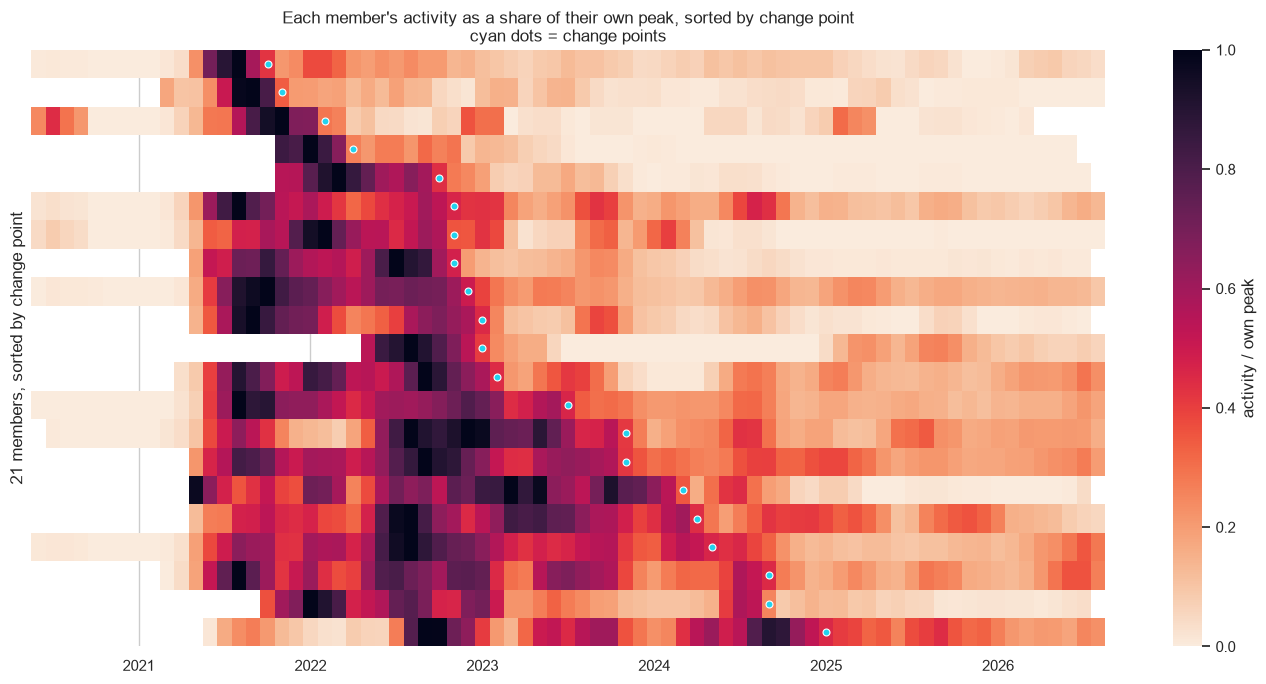

In [8]:
order = cps.sort_values("change_point")["member"].tolist()
grid = []
for who in order:
    g = member_series(who).set_index("month")["messages"]
    t3 = g.rolling(3, min_periods=1).mean()
    grid.append((t3 / t3.max()).rename(who))
H = pd.concat(grid, axis=1).T
H = H.reindex(columns=sorted(act["month"].unique()))

no_cp = [w for w in analysis if w not in order]
dash_rows = []
for who in order + no_cp:
    g = member_series(who).set_index("month")["messages"]
    t3 = g.rolling(3, min_periods=1).mean()
    cp = cps.loc[cps["member"] == who, "change_point"]
    for month, v in (t3 / t3.max()).items():
        dash_rows.append({"member": who, "month": month, "pct_of_peak": v,
                          "row_order": (order + no_cp).index(who) + 1,
                          "is_change_point": bool(len(cp)) and cp.iloc[0] == month})
pd.DataFrame(dash_rows).to_csv(os.path.join(TABLES_DIR, "changepoint_grid.csv"), index=False)

fig, ax = plt.subplots(figsize=(14, 7))
sns.heatmap(H, cmap="rocket_r", ax=ax, vmin=0, vmax=1, cbar_kws={"label": "activity / own peak"},
            linewidths=0, xticklabels=False, yticklabels=False)
cols = list(H.columns)
for i, who in enumerate(order):
    cp = cps.loc[cps["member"] == who, "change_point"].iloc[0]
    ax.plot(cols.index(cp) + 0.5, i + 0.5, marker="o", markersize=5,
            color="#22d3ee", markeredgecolor="white", markeredgewidth=0.8)
tick_at = [i for i, c in enumerate(cols) if pd.Timestamp(c).month == 1]
ax.set_xticks([i + 0.5 for i in tick_at])
ax.set_xticklabels([pd.Timestamp(cols[i]).year for i in tick_at], rotation=0)
ax.set_ylabel(f"{len(order)} members, sorted by change point")
ax.set_xlabel("")
ax.set_title("Each member's activity as a share of their own peak, sorted by change point\n"
             "cyan dots = change points",
             fontsize=12)
fig.tight_layout()
fig.savefig(os.path.join(CHARTS_DIR, "18_changepoint_heatmap.png"), dpi=150)
plt.show()

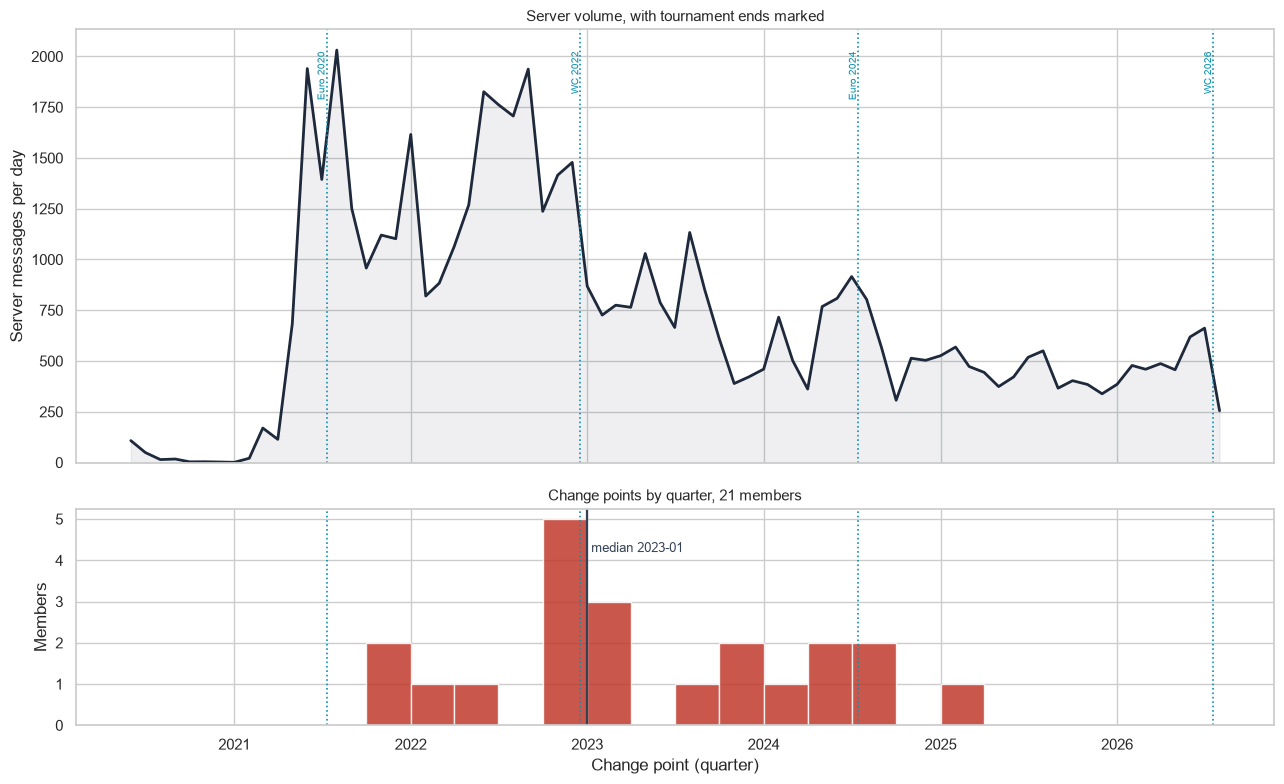

change_point
2021Q4    2
2022Q1    1
2022Q2    1
2022Q4    5
2023Q1    3
2023Q3    1
2023Q4    2
2024Q1    1
2024Q2    2
2024Q3    2
2025Q1    1
Freq: Q-DEC


In [9]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(13, 8), sharex=True,
                               gridspec_kw={"height_ratios": [2, 1]})

ax1.plot(srv["month"], srv["messages_per_day"], color="#1e293b", linewidth=2)
ax1.fill_between(srv["month"], srv["messages_per_day"], color="#1e293b", alpha=0.07)
for n, e in TOURNAMENT_ENDS.items():
    ax1.axvline(pd.Timestamp(e), color="#0891b2", linestyle=":", linewidth=1.2)
    ax1.annotate(n, (pd.Timestamp(e), ax1.get_ylim()[1] * 0.95), rotation=90,
                 fontsize=7.5, color="#0891b2", ha="right", va="top")
ax1.set_ylabel("Server messages per day")
ax1.set_ylim(bottom=0)
ax1.set_title("Server volume, with tournament ends marked", fontsize=11)

bins = pd.date_range("2021-01-01", "2025-07-01", freq="QS")
ax2.hist(cps["change_point"], bins=bins, color="#c0392b", alpha=0.85, edgecolor="white")
for n, e in TOURNAMENT_ENDS.items():
    ax2.axvline(pd.Timestamp(e), color="#0891b2", linestyle=":", linewidth=1.2)
ax2.axvline(cps["change_point"].median(), color="#334155", linewidth=1.6)
ax2.annotate(f" median {cps['change_point'].median():%Y-%m}",
             (cps["change_point"].median(), ax2.get_ylim()[1] * 0.8), fontsize=9, color="#334155")
ax2.set_ylabel("Members")
ax2.set_xlabel("Change point (quarter)")
ax2.set_title(f"Change points by quarter, {len(cps)} members",
              fontsize=11)
ax2.xaxis.set_major_locator(mdates.YearLocator())
ax2.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))

fig.tight_layout()
fig.savefig(os.path.join(CHARTS_DIR, "19_changepoint_distribution.png"), dpi=150)
plt.show()

print(cps["change_point"].dt.to_period("Q").value_counts().sort_index().to_string())

## The three excluded members

Excluded from the distribution because their change points have a known cause: two left the
server and one went dormant.

In [10]:
rows = []
for who in departed:
    cp, pk, pv = change_point(who, 0.50, min_tail=0)
    g = member_series(who)
    rows.append({"member": who, "change_point": cp, "peak_month": pk,
                 "last_active_month": g["month"].max(),
                 "lifetime_messages": int(span.loc[span["pseudonym"] == who,
                                                   "lifetime_messages"].iloc[0])})
dep = pd.DataFrame(rows)
print(dep.to_string(index=False))
print()

 member change_point peak_month last_active_month  lifetime_messages
user_20   2021-10-01 2021-08-01        2023-05-01              21714
user_21   2023-04-01 2022-08-01        2023-04-01              16978
user_26   2021-09-01 2021-08-01        2022-05-01               7063



## Summary

**Change points are spread out, not clustered.** 21 of 24 members have one, spread over 39
months (2021-10 → 2025-01, median 2023-01), and the shape holds at 40%, 50% and 60%.

**The prediction was wrong.** I expected clustering, because Steps 1, 3 and 4 found the room
thinning evenly. The data shows the opposite.

**Three members have no change point.** `user_15` (+37% from 2022 to 2025) and `user_24` (+29%)
peaked during the decline and grew; `user_06` declined at half the server's rate. Their combined
share rose from 3.0% to 18.2%. Seven of the 24 gained share in all, as the room shrank around
them, but only these two grew in absolute terms.

**Peaks don't explain the spread.** Peaks span 19 months (2021-08 → 2023-03); change points span
39. The gap from peak to change point runs from **2 to 37 months** (median 12, middle half 5–20).

**What the dates don't tell you.** A change point marks the start of a member's final stretch
below half their peak, not when their decline began. **11 of the 21 dropped below half,
recovered, and only later dropped for good**, so people hit by the same thing at the same moment
could still get change points years apart. Each member's first drop below half is more bunched
(11 of 21 in 2022, median 2022-10) but still spans 29 months. So this is a description of a
staggered decline; the data can't say whether the cause was personal or shared.

**The tournament cluster.** 7 of 21 change points (33%) fall between 2022-11 and 2023-02, around
the World Cup. The rule takes the first month below 50% that never recovers, and a 1.46×
tournament spike can lift someone already declining back over their line, pushing their change
point to just after it. With a 6-month recovery window the cluster falls to **23%**, and the
spread is still 39 months, so the cluster is partly caused by the rule.

### Steps 3 and 4 together with Step 5

Steps 3 and 4 measured the room as a whole: the same hours and pace, and a core that stayed fully
connected. Step 5 measures individuals and finds them going quiet at different times. Both fit:
members posted less at different times and stayed connected to everyone else. (Whether each
person kept their own habits wasn't measured individually.)

**Limitations:**
- 21 change points from 24 members; the other three never stay below the 50% line.
- The rule is one reasonable choice. The checks vary the threshold (40%, 50%, 60%), the recovery
  requirement (a 6-month window instead of never recovering) and tournament months (removed).
  The 3-month smoothing window and the minimum-activity requirements were not varied.
- It counts messages. On characters, 19 of 24 members have a change point, spread over 49 months,
  and some dates move by years. The staircase remains, but "21 across 39 months" is specific to
  messages.
- "Never recovers" is easier to satisfy near the end of the archive. The latest change point
  (2025-01) still has 19 months of data after it.
- The two members who arrived in 2024 are excluded: they have no earlier peak to decline from.
- Personal peaks run from 2021-08 to 2026-07, so none falls in the server's tiny first months.